# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

#Load dataset

## [kaggle dataset Link](https://www.kaggle.com/datasets/ezzaldeenesmail/obesitydataset-raw-and-data-sinthetic)

In [2]:
df=pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
df.shape

(2111, 17)

## dataset info

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

## statistical summary

In [5]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


## missing values

In [6]:
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


## duplicate check

In [7]:
df.duplicated().sum()

np.int64(24)

## drop duplicate

In [8]:
df=df.drop_duplicates().reset_index(drop=True)

# Target distribution

<Axes: xlabel='count', ylabel='NObeyesdad'>

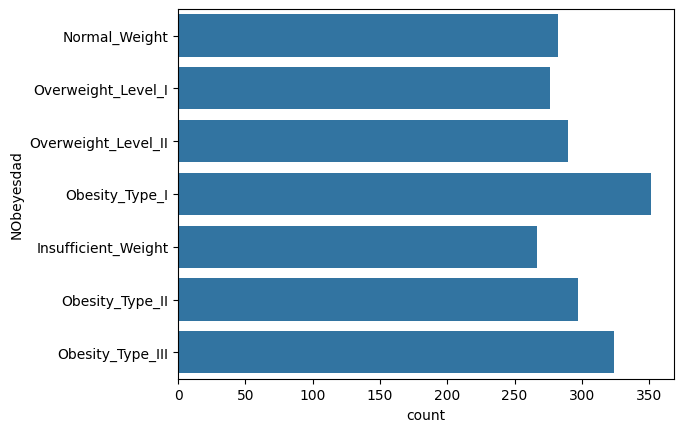

In [9]:
sns.countplot(df["NObeyesdad"])


# split X and Y

In [10]:
X=df.drop("NObeyesdad",axis=1)
y=df['NObeyesdad']

# Identify Numerical and Categorical feature

In [11]:
numerical_features=X.select_dtypes(include=['int64','float64']).columns.tolist()
numerical_features

['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

In [12]:
categorical_features=X.select_dtypes(include=['object']).columns.tolist()
categorical_features

['Gender',
 'family_history_with_overweight',
 'FAVC',
 'CAEC',
 'SMOKE',
 'SCC',
 'CALC',
 'MTRANS']

# Train Test Split

In [13]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [14]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((1669, 16), (418, 16), (1669,), (418,))

# Preprocessing Pipeline

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
numeric_transformer=Pipeline(
    steps=[
        ("scaler",StandardScaler())
    ]
)

categorical_transformer=Pipeline(
    steps=[
        ("oneHot",OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Column Transformer

In [16]:
from sklearn.compose import ColumnTransformer
preprocessor=ColumnTransformer(
    transformers=[
        ("numeric",numeric_transformer,numerical_features),
        ("categorical",categorical_transformer,categorical_features)
    ]
)

# Define Mupliple Model

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,f1_score,recall_score,precision_score

In [18]:
models={
    "LogisticRegression":LogisticRegression(),
    "DecisionTreeClassifier":DecisionTreeClassifier(),
    "RandomForestClassifier":RandomForestClassifier(),
    "GradientBoostingClassifier":GradientBoostingClassifier(),
    "KNeighborsClassifier":KNeighborsClassifier(n_neighbors=5)
}

## Create PipleLine

In [19]:
pipelines={}

for name,model in models.items():
    pipelines[name]=Pipeline(
        steps=[
            ("preprocessor",preprocessor),
            ("classifier",model)
        ]
    )

## Train All models

In [20]:
results=[]

for name,pipeline in pipelines.items():
    pipeline.fit(X_train,y_train)
    y_pred=pipeline.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred,average='weighted')
    recall=recall_score(y_test,y_pred,average='weighted')
    precision=precision_score(y_test,y_pred,average='weighted')

    results.append({
        "Model":name,
        "Accuracy":accuracy,
        "F1_Score":f1,
        "Recall":recall,
        "Precision":precision
    })
results_df=pd.DataFrame(results)

In [21]:
results_df.sort_values("F1_Score",ascending=False)

,Model,Accuracy,F1_Score,Recall,Precision
3,GradientBoostingClassifier,0.973684,0.973729,0.973684,0.973925
2,RandomForestClassifier,0.940191,0.941230,0.940191,0.943464
1,DecisionTreeClassifier,0.925837,0.925500,0.925837,0.926559
0,LogisticRegression,0.899522,0.897812,0.899522,0.897563
4,KNeighborsClassifier,0.827751,0.813609,0.827751,0.820392


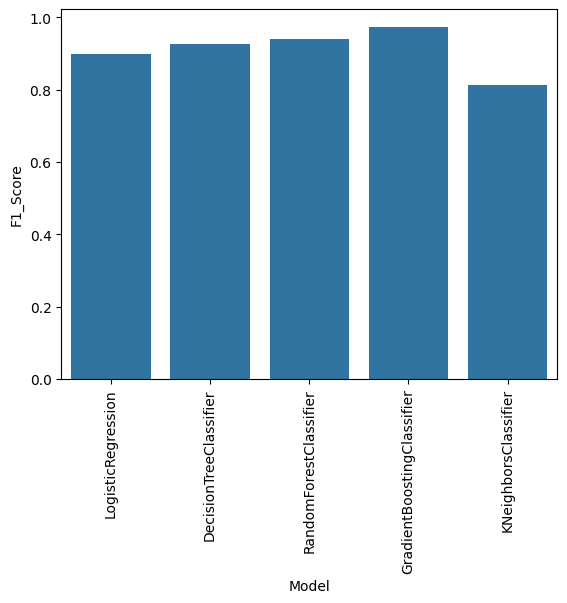

In [22]:
sns.barplot(x=results_df['Model'],y=results_df['F1_Score'])
plt.xticks(rotation=90)
plt.show()

# Cross validation

In [23]:
from sklearn.model_selection import StratifiedKFold,cross_validate

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

cv_results=[]

for name,pipeline in pipelines.items():
    scores=cross_validate(pipeline,X,y,cv=cv,scoring=["accuracy","f1_weighted","recall_weighted","precision_weighted"])

    cv_results.append({
        "Model":name,
        "Accuracy":scores["test_accuracy"].mean(),
        "F1_Score":scores["test_f1_weighted"].mean(),
        "Recall":scores["test_recall_weighted"].mean(),
        "Precision":scores["test_precision_weighted"].mean()
    })

cv_results_df=pd.DataFrame(cv_results)

In [24]:
cv_results_df.sort_values("F1_Score",ascending=False)

,Model,Accuracy,F1_Score,Recall,Precision
3,GradientBoostingClassifier,0.964554,0.964523,0.964554,0.965222
2,RandomForestClassifier,0.942018,0.942728,0.942018,0.946169
1,DecisionTreeClassifier,0.935801,0.935742,0.935801,0.937079
0,LogisticRegression,0.873991,0.872443,0.873991,0.876425
4,KNeighborsClassifier,0.831826,0.817979,0.831826,0.831060


# Hyperparameter Tuning for the best Model

 **Gradient Boosting Classifier is the best candidate**

In [25]:
gb_pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",GradientBoostingClassifier())
    ]
)

In [26]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(gb_pipeline, param_grid, cv=5, scoring="f1_weighted",n_jobs=-1,verbose=1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('numeric',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Age',
                                                                          'Height',
                                                                          'Weight',
                                                                          'FCVC',
                                                                          'NCP',
                                                                          'CH2O',
                                                                          'FAF',
                                                                          'TUE']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('oneHot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Gender',
                                                                          'family_history_with_overweight',
                                                                          'FAVC',
                                                                          'CAEC',
                                                                          'SMOKE',
                                                                          'SCC',
                                                                          'CALC',
                                                                          'MTRANS'])])),
                                       ('classifier',
                                        GradientBoostingClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__learning_rate': [0.05, 0.1],
                         'classifier__max_depth': [1, 2, 3],
                         'classifier__min_samples_leaf': [1, 2],
                         'classifier__n_estimators': [100, 200]},
             scoring='f1_weighted', verbose=1)

## best parameters & best scores

In [29]:
print("Best parameters\n")
grid_search.best_params_

Best parameters



{'classifier__learning_rate': 0.1,
 'classifier__max_depth': 3,
 'classifier__min_samples_leaf': 1,
 'classifier__n_estimators': 200}

In [34]:
print("best Cv score\n")
grid_search.best_score_

best Cv score



np.float64(0.9579140505832276)

# Final model evaluation

In [36]:
final_model=grid_search.best_estimator_
y_pred_final=final_model.predict(X_test)

In [38]:
print(classification_report(y_test,y_pred_final))

                     precision    recall  f1-score   support

Insufficient_Weight       1.00      1.00      1.00        53
      Normal_Weight       0.96      0.95      0.96        57
     Obesity_Type_I       1.00      0.99      0.99        70
    Obesity_Type_II       0.98      1.00      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.93      0.95      0.94        55
Overweight_Level_II       0.98      1.00      0.99        58

           accuracy                           0.98       418
          macro avg       0.98      0.98      0.98       418
       weighted avg       0.98      0.98      0.98       418



## confusion matrix

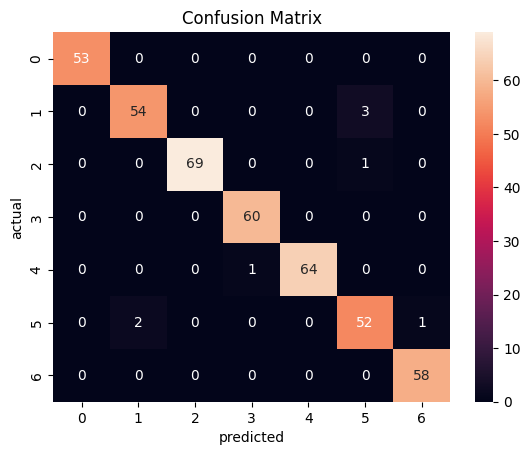

In [39]:
cm=confusion_matrix(y_test,y_pred_final)
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion Matrix")
plt.show()

# Save model

In [40]:
import joblib
joblib.dump(final_model,"obesity_classification_model.pkl")
print('Model Saved Succesfully')

Model Saved Succesfully


# Load model & make a prediction

In [41]:
loaded_model=joblib.load("obesity_classification_model.pkl")


In [42]:
loaded_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Height', 'Weight',
                                                   'FCVC', 'NCP', 'CH2O', 'FAF',
                                                   'TUE']),
                                                 ('categorical',
                                                  Pipeline(steps=[('oneHot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender',
                                                   'family_history_with_overweight',
                                                   'FAVC', 'CAEC', 'SMOKE',
                                                   'SCC', 'CALC',
                                                   'MTRANS'])])),
                ('classifier', GradientBoostingClassifier(n_estimators=200))])

## make new prediction

In [48]:
row=X_test.iloc[[0]]
print("data for prediction\n")
row

data for prediction



,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
1153,Female,19.955257,1.5891,72.713611,yes,no,3.0,3.856434,Sometimes,no,2.0,no,1.32417,1.0,Sometimes,Public_Transportation


In [50]:
prediction=loaded_model.predict(row)
prediction

array(['Overweight_Level_II'], dtype=object)

In [51]:
print("Predicted class: ",prediction[0])
print("Actual Class :",y_test.iloc[0])

Predicted class:  Overweight_Level_II
Actual Class : Overweight_Level_II


## prediction probability

In [52]:
loaded_model.predict_proba(row)

array([[1.02572284e-04, 8.65390765e-04, 3.48644631e-04, 7.10990285e-06,
        1.07621084e-08, 7.19045213e-03, 9.91485820e-01]])

In [56]:
prob_df=pd.DataFrame({
    "Class":loaded_model.classes_,
    "Probability":loaded_model.predict_proba(row)[0]
})

In [58]:
prob_df.sort_values("Probability",ascending=False)

,Class,Probability
6,Overweight_Level_II,9.914858e-01
5,Overweight_Level_I,7.190452e-03
1,Normal_Weight,8.653908e-04
2,Obesity_Type_I,3.486446e-04
0,Insufficient_Weight,1.025723e-04
3,Obesity_Type_II,7.109903e-06
4,Obesity_Type_III,1.076211e-08




---



---




**[Z.I Turjo](https://www.linkedin.com/in/zahidul-islam-turjo-609549320/)**